#  Simulation des Lois 

#  Exercice 1 

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import random as rd
from math import exp
from itertools import permutations
from math import factorial
from math import sqrt
from random import randint
import matplotlib.pyplot as plt

la probabilité de 1 est : 0.499847
la probabilité de 2 est : 0.166837
la probabilité de 3 ets : 0.333316


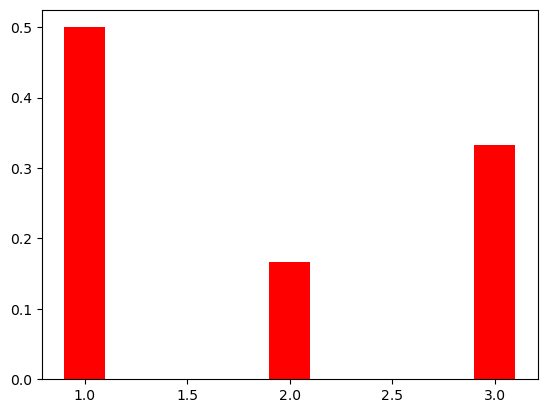

In [36]:
def partition():
    u=rd.random()
    if 0<= u < 1/2 :
        return 1
    elif 1/2<= u <2/3:
        return 2
    else:
        return 3

def smulatuionLoi(n):
    L=[]
    V=[]
    for i in range(n):
        L.append(partition())
    V.append(L.count(1)/n)
    V.append(L.count(2)/n)
    V.append(L.count(3)/n)
    absc = np.linspace(1, 3, 3)
    plt.bar(absc, V, color = 'r', width = 0.2)
    print("la probabilité de 1 est :",L.count(1)/n)
    print("la probabilité de 2 est :",L.count(2)/n)
    print("la probabilité de 3 ets :",L.count(3)/n)

smulatuionLoi(1000000)

In [37]:
def sommecumule(L):
    S=[]
    s=0
    for  x in L :
        s=s+x
        S.append(s)
    return S
#"np.cumsum(P) fournielememe resultat 

In [38]:
 # Pour estimer la probabilité, on simule plusieurs classes.
def simulationdiscret(X, P):
    R = sommecumule(P)
    u = rd.random()
    i = 0
    while (u >= R[i]):
       i = i + 1
    return X[i]


In [2]:
def bernoulli(p):
    if rd.random() < p:
        return 1
    else:
        return 0

[0.69951, 0.30049]


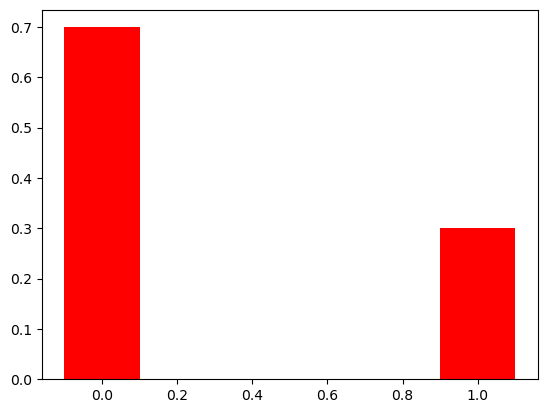

In [3]:
def main():
  N=100000 
  p=0.3
  valeurs = [bernoulli(p) for _ in range(N)]
  XX=[valeurs.count(i)/N for i in [0,1]]
  print(XX)
  absc = np.linspace(0, 1,2)
  plt.bar(absc, XX, color = 'r', width = 0.2)
main()  

En utilisant : $X=\sum X_i $

In [4]:
def binomiale_ind(n, p):
    a = 0
    for i in range(n):
        a += bernoulli(p)
    return a

En utilisant la loiu directement

In [5]:
def combinaison(n, k):
  if n == 0:
    return 0
  elif k == 0 or k == n:
    return 1
  else:
    return combinaison(n - 1, k - 1) + combinaison(n - 1, k)

In [6]:
def binomiale_inve(n, p):
  u = rd.random()
  i = -1
  c = 0
  while u >= c:
    i += 1
    c += combinaison(n, i) * p ** i * (1 - p) ** (n - i)
  return i  

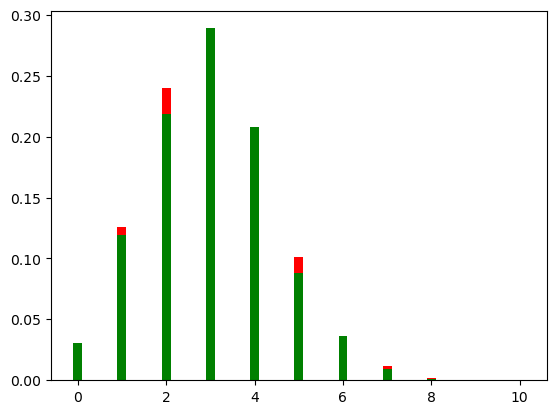

In [43]:
def main():
  N=1000 
  p=0.3
  n=10
  V1 = [binomiale_ind(n, p) for _ in range(N)]
  XX= [V1.count(i)/100000.0 for i in range(n+1)]
  V2 = [binomiale_inve(n, p) for _ in range(N)]
  X1= [V1.count(i)/N for i in range(n+1)]
  X2= [V2.count(i)/N for i in range(n+1)]
  absc = np.linspace(0, n,n+1)
  plt.bar(absc, X1, color = 'r', width = 0.2)
  plt.bar(absc, X2, color = 'g', width = 0.2)
  plt.show()
main()

[0.1695, 0.3624, 0.3014, 0.1337, 0.0306, 0.0024]


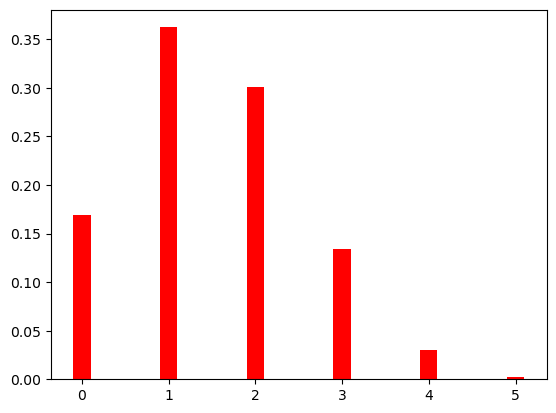

In [7]:
def combinaison(n, k):
  if n == 0:
    return 0
  elif k == 0 or k == n:
    return 1
  else:
    return combinaison(n - 1, k - 1) + combinaison(n - 1, k)
def binomialev2(n, p):
  u = rd.random()
  i = -1
  c = 0
  while u >= c:
    i += 1
    c += combinaison(n, i) * p ** i * (1 - p) ** (n - i)
  return i     
def main():
  N=10000
  p=0.3
  n=5
  valeurs = [binomialev2(n, p) for _ in range(N)]
  XX= [valeurs.count(i)/N for i in range(0,n+1)]
  print(XX)
  absc = np.linspace(0, n,n+1)
  plt.bar(absc, XX, color = 'r', width = 0.2)
main()  

In [48]:
def geometric(p, n=50):
    X = [i for i in range(n+1)]
    P = [(p**i) * (1-p)**(n-i) for i in range(n+1)]
    return simulationdiscret(X,P)

In [52]:
n=50

In [53]:
def main():
  p = 0.3

  V1 = [geometric(p, n=50) for _ in range(n)]

  X1= [V1.count(i)/n for i in range(n+1)]

  k = np.arange(1, n+1)
  p_theo = p*(1-p)**(k-1)

  plt.figure(figsize=(10,6))
  plt.bar(k, X1 , alpha=0.6, color='skyblue', label='Simulation')

  plt.plot(k, p_theo, 'ro-', linewidth=2, label='Théorie')

  plt.xlabel("k")
  plt.ylabel("Probabilité")
  plt.title("Loi géométrique : simulation discrète vs théorie")
  plt.legend()
  plt.grid()
  plt.show()
 
main()

IndexError: list index out of range